# Report 2: learned Cropr token pruning

All model loading, normalization, task heads and Cropr construction live in
`cropr.py`. The runner constructs one model/task at a time. Existing datasets,
weights and Report 1 are read only; all results go into `report_2/cropr measurements`.

Classification uses one auxiliary query per stage and allows pruning without
fusion. Segmentation uses one query per patch-grid position and requires
last-layer fusion to restore full token count and original spatial order.
Both train with main task loss plus an auxiliary loss that teaches the scorer.
The pretrained backbone stays frozen. No cached features or LoRA are used.

The measurement methods and report panels match Report 1. LoRA/cache-specific
fields are N/A; Cropr/token fields are additional. One pruning variant per run.


In [1]:
import sys
import os
import importlib
from pathlib import Path

# Resolve shared assets and imports without changing the working directory.
PROJECT_ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                     if (p / "models").is_dir() and (p / "report_1").is_dir()
                     and (p / "report_2").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the Deep Learning Project directory.")
ROOT = PROJECT_ROOT
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
REPORT1_DIR = PROJECT_ROOT / "report_1"
REPORT2_DIR = PROJECT_ROOT / "report_2"

if str(REPORT2_DIR) not in sys.path:
    sys.path.insert(0, str(REPORT2_DIR))
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["XFORMERS_DISABLED"] = "1"

import torch
import cropr
import report2_cropr_runner as runner
importlib.reload(cropr)
importlib.reload(runner)
ROOT = PROJECT_ROOT
torch.set_num_threads(1)  # Same CPU-thread setting as Report 1.
print("Model setup:", cropr.__file__)
print("Runner:", runner.__file__)
print("Dataset/model root:", ROOT)


Model setup: /root/work/DeepLearning-Project/report_2/cropr.py
Runner: /root/work/DeepLearning-Project/report_2/report2_cropr_runner.py
Dataset/model root: /root/work/DeepLearning-Project


## Experiment settings
Choose models, tasks and one pruning variant.


In [2]:
# Local smoke settings (448x448, one epoch on the existing saved splits).
# Keep these non-Cropr settings matched in both notebooks for a controlled comparison.
# RTX 4090 comments are suggested starting points, not measured memory limits.
SEED = 42
SIZE = 448  # RTX 4090: keep 448x448.
MODEL_NAMES = ("dinov2", "siglip2",) # "dinov2", "siglip2", "radio"
TASKS = ("classification", "segmentation")
EPOCHS = {"classification": 10, "segmentation": 20}  # RTX 4090: {"classification": 10, "segmentation": 20}.

# Identical LoRA and task-head optimization in both reports.
LORA_R = 8
LORA_ALPHA = 16.0
LORA_LR = 1e-4
LORA_TARGETS = None
LR = {"classification": 1e-3, "segmentation": 1e-3}
WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 1.0
TRAIN_PRECISION = "bf16"
EVAL_TF32 = False
STRICT_DETERMINISM = False

# Effective training batch = microbatch x accumulation = 16 on either machine.
MICRO_BATCH_SIZE = 8  # RTX 4090: start with 4, including Cropr segmentation.
GRAD_ACCUM_STEPS = 2  # RTX 4090: 4 when microbatch is 4.
EVAL_BATCH_SIZE = 16  # RTX 4090: start with 8; evaluation is FP32.
BATCH_SIZE = 2  # Keep benchmark batch 2 in both reports for comparable timings.
NUM_WORKERS = 16  # RTX 4090 cloud host: try 8 if CPU/storage support it.
LOADER_BACKEND = "thread"
FAIL_FAST = True

# Short smoke measurements; use the commented settings for final measurements.
BENCH_WARMUP = 2  # RTX 4090 / final measurements: 10.
BENCH_REPEATS = 5  # RTX 4090 / final measurements: 50.
BENCH_TRIALS = 1  # RTX 4090 / final measurements: 3.
FLOP_BATCHES = 1  # RTX 4090 / final measurements: 3.
PROFILE_REPEATS = 1  # RTX 4090 / final measurements: 3.

# Cropr-only additions to the baseline model and training.
VARIANT = "gradual_llf"  # "gradual_llf", "three_stage_llf", "gradual_no_llf"
# For gradual_no_llf, set TASKS = ("classification",). Segmentation requires fusion.
PRUNING_RATE = 8         # Patch tokens removed per gradual stage; not a percentage.
CROPR_LR = 1e-4
AUX_WEIGHT = 1.0
NUM_HEADS = 1

print("Experiments:", [(task, name, VARIANT) for task in TASKS for name in MODEL_NAMES])
print("Effective training batch:", MICRO_BATCH_SIZE * GRAD_ACCUM_STEPS)


Experiments: [('classification', 'dinov2', 'gradual_llf'), ('classification', 'siglip2', 'gradual_llf'), ('segmentation', 'dinov2', 'gradual_llf'), ('segmentation', 'siglip2', 'gradual_llf')]
Effective training batch: 16


## Training run
This cell starts the full selected run.


In [10]:
# TRAINING RUN ? execute this cell to train, evaluate, save checkpoints and measure.
# This uses the existing ImageNet/ADE20K saved splits; it does not recreate them.
results, OUT = runner.run_cropr(
    ROOT=ROOT, SEED=SEED, SIZE=SIZE, MODEL_NAMES=MODEL_NAMES, TASKS=TASKS,
    VARIANT=VARIANT, PRUNING_RATE=PRUNING_RATE, NUM_HEADS=NUM_HEADS,
    CROPR_LR=CROPR_LR, AUX_WEIGHT=AUX_WEIGHT,
    LORA_R=LORA_R, LORA_ALPHA=LORA_ALPHA, LORA_LR=LORA_LR, LORA_TARGETS=LORA_TARGETS,
    EPOCHS=EPOCHS, LR=LR, WEIGHT_DECAY=WEIGHT_DECAY,
    TRAIN_PRECISION=TRAIN_PRECISION, MAX_GRAD_NORM=MAX_GRAD_NORM,
    MICRO_BATCH_SIZE=MICRO_BATCH_SIZE, GRAD_ACCUM_STEPS=GRAD_ACCUM_STEPS,
    EVAL_BATCH_SIZE=EVAL_BATCH_SIZE, BATCH_SIZE=BATCH_SIZE,
    NUM_WORKERS=NUM_WORKERS, LOADER_BACKEND=LOADER_BACKEND, FAIL_FAST=FAIL_FAST,
    STRICT_DETERMINISM=STRICT_DETERMINISM,
    EVAL_TF32=EVAL_TF32, BENCH_WARMUP=BENCH_WARMUP, BENCH_REPEATS=BENCH_REPEATS,
    BENCH_TRIALS=BENCH_TRIALS, FLOP_BATCHES=FLOP_BATCHES, PROFILE_REPEATS=PROFILE_REPEATS,
)
print("Run folder:", OUT)
print("Checkpoints: best_cropr.pt / last_cropr.pt (LoRA adapters + task head + all learned pruners)")
print("Measurements:", OUT / "cropr measurements.csv")


Validate classification/train:   0%|          | 0/100000 [00:00<?, ?files/s]

Validate classification/dev:   0%|          | 0/20000 [00:00<?, ?files/s]

Validate classification/val:   0%|          | 0/50000 [00:00<?, ?files/s]

classification {'train': 100000, 'dev': 20000, 'val': 50000}


Validate segmentation/train:   0%|          | 0/18189 [00:00<?, ?files/s]

...

  main=0.2564, aux=11.2918 | dev miou_pct=46.62 | peak=8.51 GiB


USDT:2026-10-27 06:40:13 1109049:1109049 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-27 06:40:13 1109049:1109049 SyncActivityProfilerHandler.cpp:46] profiler_stop
[W1027 06:40:13.077481013 util.cpp:833] Warning: Failed to compute flops for op aten::conv2d because it requires padding, stride, and dilation values. (function computeFlops)


Evaluate segmentation:   0%|          | 0/125 [00:00<?, ?batch/s]

USDT:2026-10-27 06:40:34 1109049:1109049 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-27 06:40:34 1109049:1109049 SyncActivityProfilerHandler.cpp:46] profiler_stop
[W1027 06:40:34.698495949 util.cpp:833] Warning: Failed to compute flops for op aten::conv2d because it requires padding, stride, and dilation values. (function computeFlops)



Finished.  Measurements saved to:
/root/work/DeepLearning-Project/report_2/cropr measurements/cropr measurements.csv
/root/work/DeepLearning-Project/report_2/cropr measurements/dinov2/latest/cropr measurements.csv
/root/work/DeepLearning-Project/report_2/cropr measurements/siglip2/latest/cropr measurements.csv
classification dinov2 → completed
classification siglip2 → completed
segmentation dinov2 → completed
segmentation siglip2 → completed
Run folder: /root/work/DeepLearning-Project/report_2/cropr measurements
Checkpoints: best_cropr.pt / last_cropr.pt (LoRA adapters + task head + all learned pruners)
Measurements: /root/work/DeepLearning-Project/report_2/cropr measurements/cropr measurements.csv


## Report metrics ? same panels as Report 1


In [5]:
# Refresh profiler attribution only; this reuses Cropr checkpoints and does not train.
importlib.reload(cropr)
importlib.reload(runner)

if not torch.cuda.is_available():
    raise RuntimeError("Select the CUDA notebook kernel before profiling.")

RUN_FOLDER = REPORT2_DIR / "cropr measurements"

targets = [
    ("dinov2", ("classification", "segmentation")),
    ("radio", ("classification","segmentation")),
    ("siglip2", ("classification","segmentation")),
]

for model_name, tasks_to_refresh in targets:
    refreshed_rows, _ = runner.refresh_component_timings(
        RUN_FOLDER,
        ROOT=ROOT,
        MODEL_NAMES=(model_name,),
        TASKS=tasks_to_refresh,
        PROFILE_REPEATS=10,
        WARMUP=10,
    )
    for row in refreshed_rows:
        print(row["model"], row["task"],
              "available:", row.get("component_gpu_attribution_available"),
              "reason:", row.get("component_gpu_attribution_reason"))

USDT:2026-10-27 14:10:11 1950858:1950858 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-27 14:10:12 1950858:1950858 SyncActivityProfilerHandler.cpp:46] profiler_stop


dinov2 classification available: True reason: 


USDT:2026-10-27 14:10:16 1950858:1950858 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-27 14:10:16 1950858:1950858 SyncActivityProfilerHandler.cpp:46] profiler_stop


dinov2 segmentation available: True reason: 
Previous profiling outputs backed up to: /root/work/DeepLearning-Project/report_2/cropr measurements/component timing backups/20261027_141009_395312
dinov2 classification available: True reason: 
dinov2 segmentation available: True reason: 


USDT:2026-10-27 14:10:21 1950858:1950858 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-27 14:10:21 1950858:1950858 SyncActivityProfilerHandler.cpp:46] profiler_stop


...

radio segmentation available: True reason: 
Previous profiling outputs backed up to: /root/work/DeepLearning-Project/report_2/cropr measurements/component timing backups/20261027_141019_104062
radio classification available: True reason: 
radio segmentation available: True reason: 


[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.
USDT:2026-10-27 14:10:38 1950858:1950858 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-27 14:10:38 1950858:1950858 SyncActivityProfilerHandler.cpp:46] profiler_stop


siglip2 classification available: True reason: 


USDT:2026-10-27 14:10:49 1950858:1950858 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-27 14:10:49 1950858:1950858 SyncActivityProfilerHandler.cpp:46] profiler_stop


siglip2 segmentation available: True reason: 
Previous profiling outputs backed up to: /root/work/DeepLearning-Project/report_2/cropr measurements/component timing backups/20261027_141027_499957
siglip2 classification available: True reason: 
siglip2 segmentation available: True reason: 


Results: /root/work/DeepLearning-Project/report_2/cropr measurements
Training mode: cropr
Completed experiments: 6 / 6


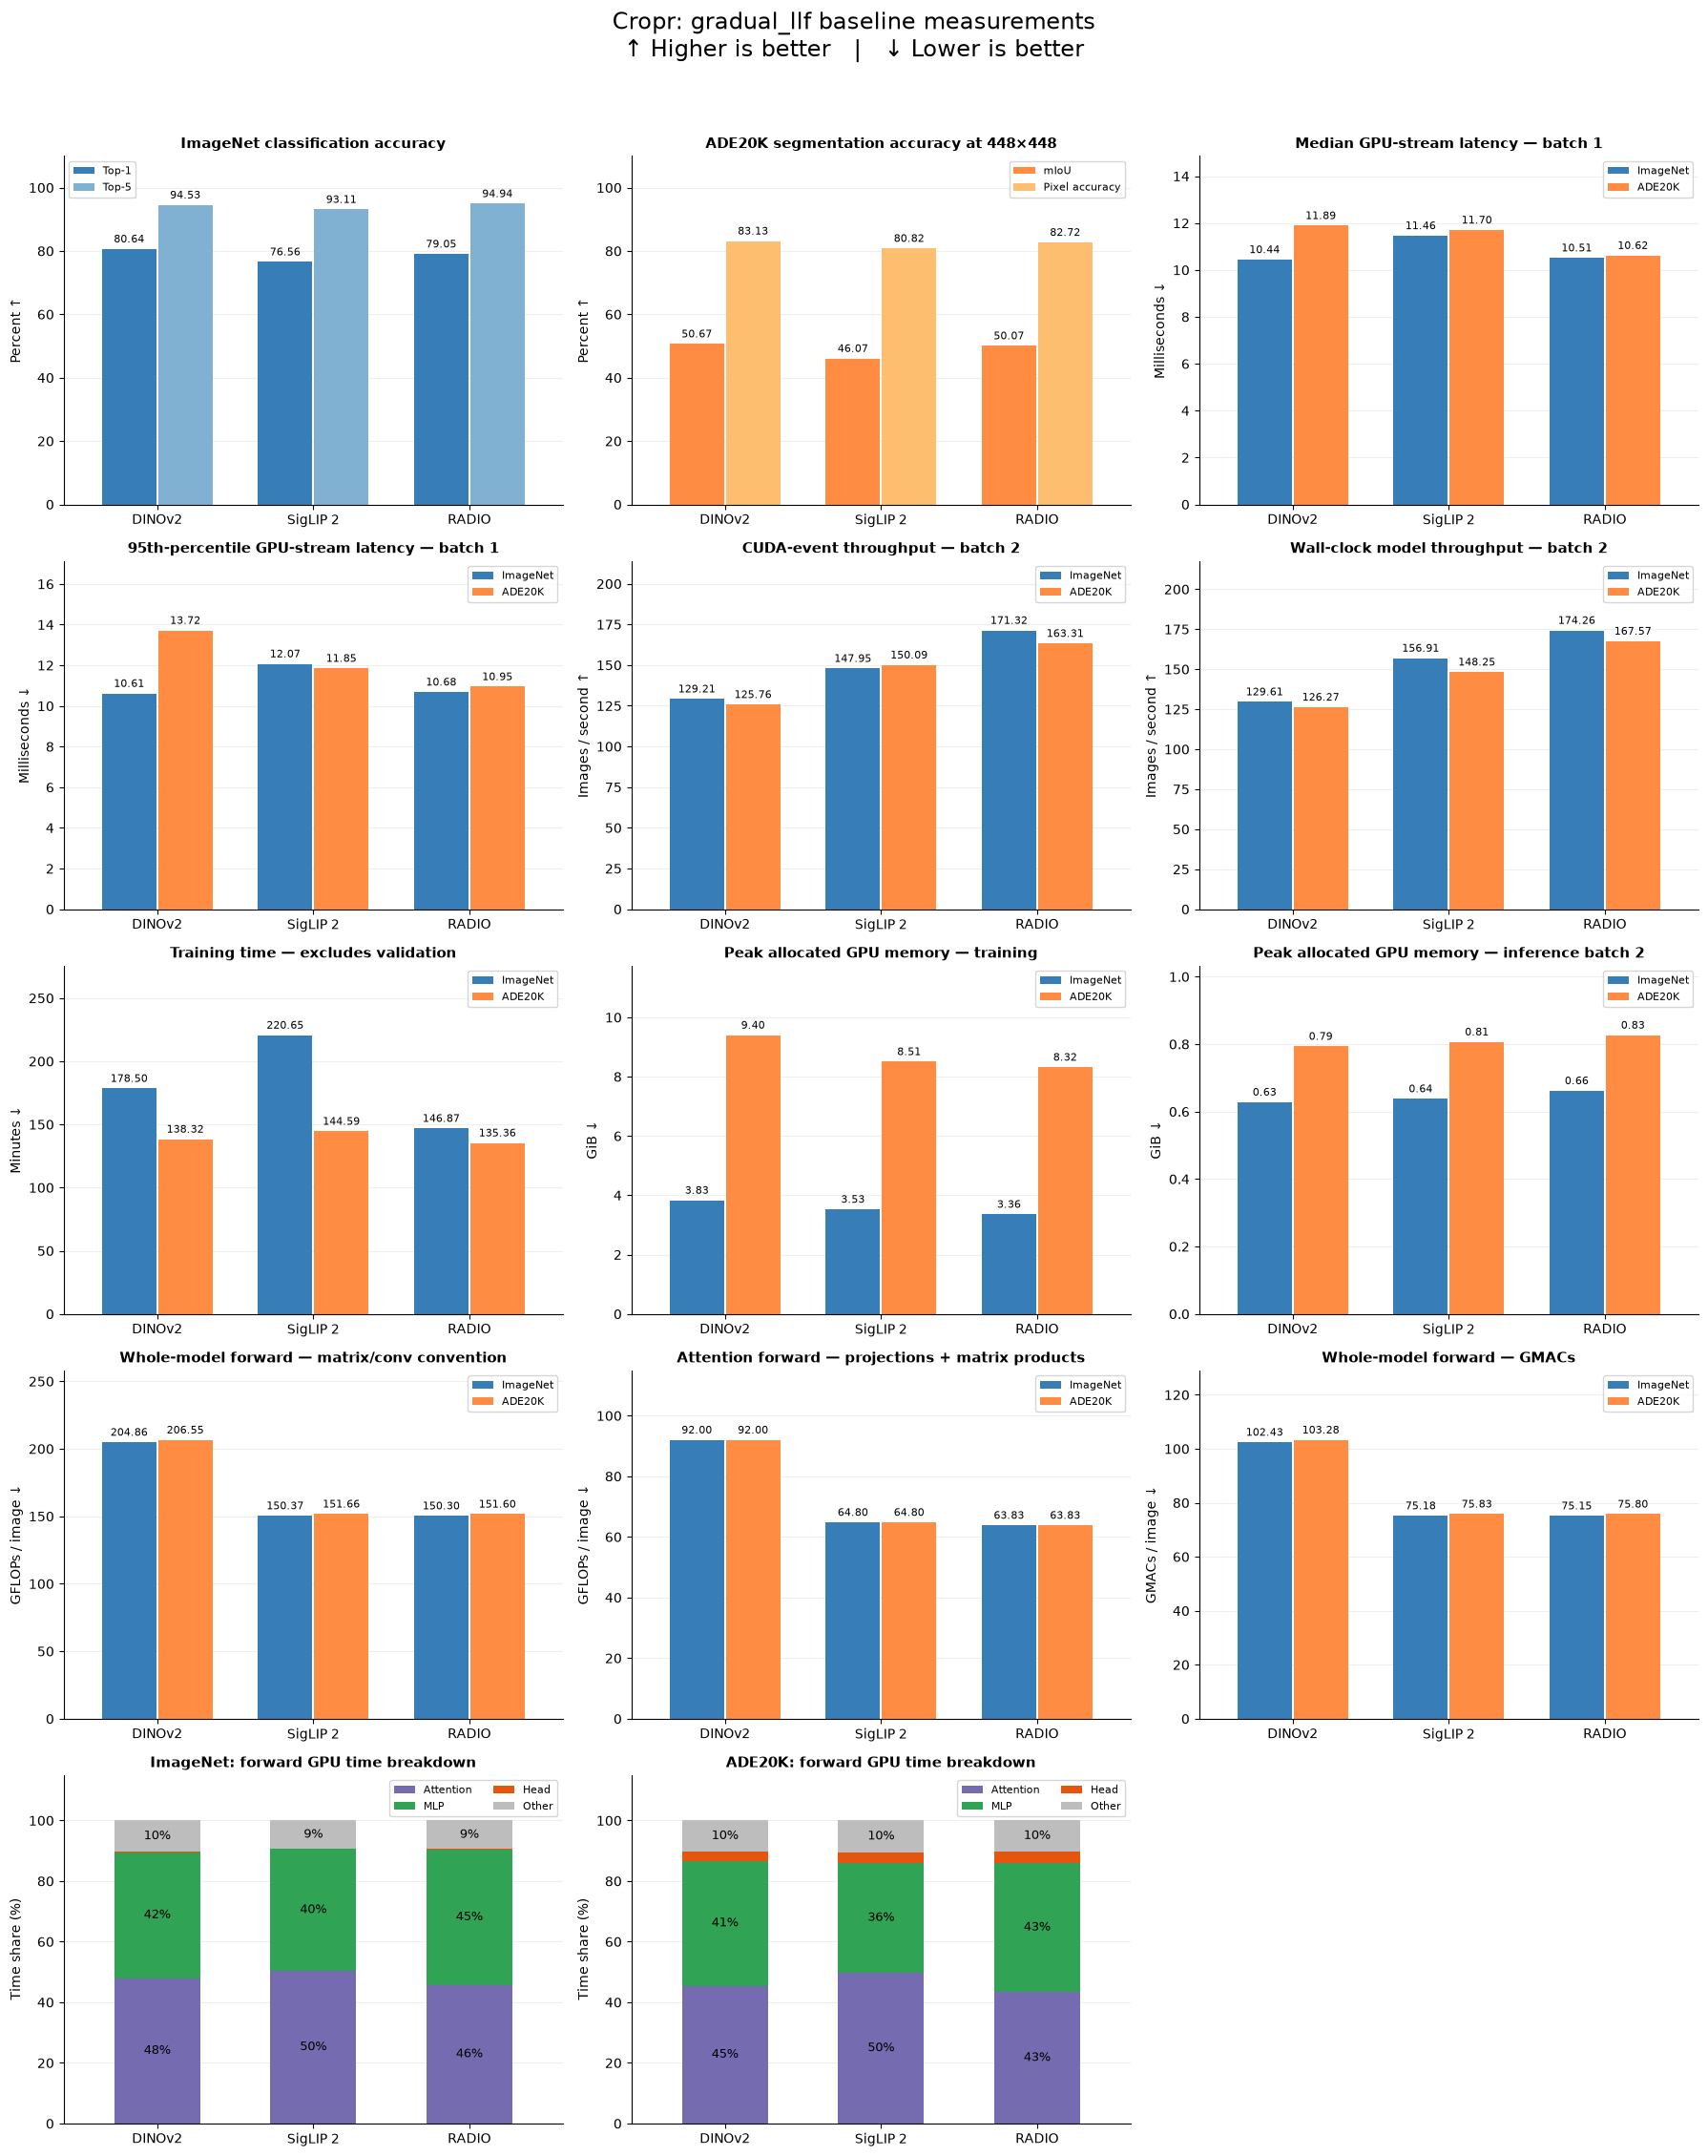

Training time scope: RGB loading + main/auxiliary forward/backward + optimizer; excludes dev and audits
Inference uses the RGB Cropr model with auxiliary aggregation/heads skipped.
Forward counts: matrix multiplications, convolutions, and dense attention products.
Convention: 2 FLOPs per MAC; GMACs = GFLOPs / 2.
Excludes softmax, normalization, activations, interpolation, pooling, sorting, and elementwise work.
Coverage flags refer to this convention, not every arithmetic instruction.
Legacy partial profiler FLOPs are not used in these compute plots.
Throughput error bars show sample standard deviation across timing trials.
With one timing trial, no standard-deviation error bar is available.
Inference timing excludes data loading and GPU transfers.
Wall-clock throughput includes CPU launch overhead.
GPU-time shares are not FLOP shares.
Compare training time only with matching epoch budgets and dataset sizes.


In [6]:
from pathlib import Path
# REPORT METRICS ? no training in the cells below.
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
TRAINING_MODE = "cropr"

# Graphs always read each model's stable latest folder; they do not use OUT.
RUN_FOLDER = REPORT2_DIR / "cropr measurements"


def load_selected_run(folder=None):
    run_path = Path(folder or RUN_FOLDER).expanduser().resolve()
    latest_files = sorted(run_path.glob("*/latest/cropr measurements.csv"))
    if latest_files:
        raw = pd.concat([pd.read_csv(path) for path in latest_files], ignore_index=True)
        configs = [json.loads((path.parent / "configuration.json").read_text(encoding="utf-8")) for path in latest_files]
        config = configs[0]
        if any(item.get("training_mode") != config.get("training_mode") for item in configs[1:]):
            raise ValueError("Latest model folders contain mixed training modes.")
    else:
        # Explicit legacy timestamped run folder.
        config = json.loads((run_path / "configuration.json").read_text(encoding="utf-8"))
        raw = pd.read_csv(run_path / "cropr measurements.csv")
    completed = raw.loc[raw["status"].eq("completed")].copy()
    if completed.empty:
        raise ValueError(f"No completed experiments in {run_path}.  Inspect the runner's error files.")
    if "training_mode" not in completed:
        completed["training_mode"] = config.get("training_mode", "unknown")
    modes = completed["training_mode"].dropna().unique()
    if len(modes) != 1 or modes[0] != "cropr":
        raise ValueError("Select one Cropr run at a time.")
    mode = str(modes[0])
    if config.get("training_mode", mode) != mode:
        raise ValueError("Results and run configuration disagree about training mode.")
    if mode == "lora":
        if "inference_lora_merged" not in completed or not completed["inference_lora_merged"].astype(str).str.lower().isin(["true", "1", "1.0"]).all():
            raise ValueError("LoRA inference rows must record merged adapters.")
    if completed.duplicated(["task", "model"]).any():
        raise ValueError("Duplicate task/model rows found.")
    return run_path, config, raw, completed, mode


run, run_config, results, df, training_mode = load_selected_run(RUN_FOLDER)
mode_label = "Cropr: " + run_config["cropr_variant"]
print("Results:", run)
print("Training mode:", training_mode)
print(f"Completed experiments: {len(df)} / {len(results)}")

models = ["dinov2", "siglip2", "radio"]
model_labels = ["DINOv2", "SigLIP 2", "RADIO"]
tasks = ["classification", "segmentation"]
task_labels = ["ImageNet", "ADE20K"]
colors = ["#377eb8", "#ff8c42"]

batches = pd.to_numeric(df["batch_size"], errors="coerce").dropna().unique()
if len(batches) != 1:
    raise ValueError("Use the same batch size across experiments.")
batch = int(batches[0])

resolutions = pd.to_numeric(
    df["resolution"], errors="coerce"
).dropna().unique()
if len(resolutions) != 1:
    raise ValueError("Use the same resolution across experiments.")
size = int(resolutions[0])

df["training_minutes"] = pd.to_numeric(
    df["training_seconds"], errors="coerce"
) / 60

WHOLE = "whole_model_forward_gflops_per_image"
ATTENTION = "attention_forward_gflops_per_image"
GMACS = "whole_model_forward_gmacs_per_image"

coverage_flags = {
    WHOLE: "whole_model_flops_coverage_ok",
    ATTENTION: "attention_flops_coverage_ok",
    GMACS: "whole_model_flops_coverage_ok",
}


def true_flags(series):
    return (
        series.astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "1.0"])
    )


def values(task, metric):
    subset = df.loc[df["task"] == task].set_index("model")

    if metric not in subset:
        return np.full(len(models), np.nan)

    data = pd.to_numeric(subset[metric], errors="coerce")

    flag = coverage_flags.get(metric)
    if metric.endswith("_gpu_time_pct"):
        flag = "component_gpu_attribution_available"

    if flag is not None:
        if flag not in subset:
            return np.full(len(models), np.nan)
        data = data.where(true_flags(subset[flag]))

    return data.reindex(models).to_numpy(dtype=float)


def setup_axis(ax, title, ylabel):
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.set_xticks(np.arange(len(models)), model_labels)
    ax.set_xlim(-0.6, len(models) - 0.4)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def bars(ax, x, y, color, label, errors=None):
    valid = np.isfinite(y)
    if not valid.any():
        return []

    plotted = ax.bar(
        x[valid], y[valid], width=0.35,
        color=color, label=label,
    )
    ax.bar_label(
        plotted,
        labels=[f"{v:.2f}" for v in y[valid]],
        padding=3, fontsize=8,
    )

    upper = y[valid].tolist()

    if errors is not None:
        valid_error = valid & np.isfinite(errors) & (errors >= 0)
        if valid_error.any():
            ax.errorbar(
                x[valid_error], y[valid_error],
                yerr=errors[valid_error],
                fmt="none", ecolor="black", capsize=4,
            )
            upper.extend((y[valid_error] + errors[valid_error]).tolist())

    return upper


def comparison(ax, metric, title, ylabel, error_metric=None):
    setup_axis(ax, title, ylabel)
    upper = []

    for i, task in enumerate(tasks):
        x = np.arange(len(models)) + (i - 0.5) * 0.36
        errors = values(task, error_metric) if error_metric else None
        upper.extend(
            bars(
                ax, x, values(task, metric),
                colors[i], task_labels[i], errors,
            )
        )

    maximum = max(upper) if upper else 0
    ax.set_ylim(0, maximum * 1.25 if maximum > 0 else 1)

    if upper:
        ax.legend(fontsize=8)
    else:
        message = (
            "Missing / coverage not verified"
            if metric in coverage_flags else "Not available"
        )
        ax.text(
            0.5, 0.5, message,
            transform=ax.transAxes,
            ha="center", va="center", fontsize=9,
        )


fig, axes = plt.subplots(5, 3, figsize=(18, 23))
axes = axes.ravel()

# Accuracy.
accuracy_panels = [
    (
        axes[0], "classification",
        "ImageNet classification accuracy",
        [
            ("heldout_top1_pct", "Top-1", "#377eb8"),
            ("heldout_top5_pct", "Top-5", "#80b1d3"),
        ],
    ),
    (
        axes[1], "segmentation",
        f"ADE20K segmentation accuracy at {size}×{size}",
        [
            ("heldout_miou_pct", "mIoU", "#ff8c42"),
            ("heldout_pixel_accuracy_pct", "Pixel accuracy", "#fdbf6f"),
        ],
    ),
]

for ax, task, title, metrics in accuracy_panels:
    setup_axis(ax, title, "Percent ↑")
    for i, (metric, label, color) in enumerate(metrics):
        x = np.arange(len(models)) + (i - 0.5) * 0.36
        bars(ax, x, values(task, metric), color, label)
    ax.set_ylim(0, 110)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=8)

# Speed, memory, and corrected forward counts.
panels = [
    (
        "b1_latency_median_ms",
        "Median GPU-stream latency — batch 1",
        "Milliseconds ↓", None,
    ),
    (
        "b1_latency_p95_ms",
        "95th-percentile GPU-stream latency — batch 1",
        "Milliseconds ↓", None,
    ),
    (
        f"b{batch}_images_per_second",
        f"CUDA-event throughput — batch {batch}",
        "Images / second ↑",
        f"b{batch}_images_per_second_std",
    ),
    (
        f"b{batch}_wall_images_per_second",
        f"Wall-clock model throughput — batch {batch}",
        "Images / second ↑",
        f"b{batch}_wall_images_per_second_std",
    ),
    (
        "training_minutes",
        "Training time — excludes validation",
        "Minutes ↓", None,
    ),
    (
        "train_peak_allocated_gib",
        "Peak allocated GPU memory — training",
        "GiB ↓", None,
    ),
    (
        f"b{batch}_peak_allocated_gib",
        f"Peak allocated GPU memory — inference batch {batch}",
        "GiB ↓", None,
    ),
    (
        WHOLE,
        "Whole-model forward — matrix/conv convention",
        "GFLOPs / image ↓", None,
    ),
    (
        ATTENTION,
        "Attention forward — projections + matrix products",
        "GFLOPs / image ↓", None,
    ),
    (
        GMACS,
        "Whole-model forward — GMACs",
        "GMACs / image ↓", None,
    ),
]

for ax, (metric, title, ylabel, error_metric) in zip(axes[2:12], panels):
    comparison(ax, metric, title, ylabel, error_metric)

# GPU-time breakdown.
parts = ["attention", "mlp", "head", "other"]
part_colors = ["#756bb1", "#31a354", "#e6550d", "#bdbdbd"]

for ax, task, label in zip(axes[12:14], tasks, task_labels):
    setup_axis(ax, f"{label}: forward GPU time breakdown", "Time share (%)")

    data = np.array([
        values(task, f"{part}_gpu_time_pct") for part in parts
    ])
    valid = np.isfinite(data).all(axis=0)
    x = np.arange(len(models))[valid]
    bottom = np.zeros(valid.sum())

    if valid.any():
        for i, part in enumerate(parts):
            heights = data[i, valid]
            ax.bar(
                x, heights, bottom=bottom, width=0.55,
                color=part_colors[i],
                label="MLP" if part == "mlp" else part.title(),
            )
            for position, height, base in zip(x, heights, bottom):
                if height >= 7:
                    ax.text(
                        position, base + height / 2, f"{height:.0f}%",
                        ha="center", va="center", fontsize=9,
                    )
            bottom += heights

        ax.legend(fontsize=8, ncol=2)

        for position in np.arange(len(models))[~valid]:
            ax.text(position, 3, "N/A", ha="center", color="gray")
    else:
        ax.text(
            0.5, 0.5, "GPU attribution unavailable",
            transform=ax.transAxes, ha="center", va="center",
        )

    ax.set_ylim(0, 115)

axes[14].set_visible(False)

fig.suptitle(
    f"{mode_label} baseline measurements\n"
    "↑ Higher is better   |   ↓ Lower is better",
    fontsize=17,
)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

print("Training time scope:", run_config.get("training_seconds_scope", "See result.json"))
print("Inference uses the RGB Cropr model with auxiliary aggregation/heads skipped.")
print(
    "Forward counts: matrix multiplications, convolutions, and dense attention products.\n"
    "Convention: 2 FLOPs per MAC; GMACs = GFLOPs / 2.\n"
    "Excludes softmax, normalization, activations, interpolation, pooling, "
    "sorting, and elementwise work.\n"
    "Coverage flags refer to this convention, not every arithmetic instruction.\n"
    "Legacy partial profiler FLOPs are not used in these compute plots.\n"
    "Throughput error bars show sample standard deviation across timing trials.\n"
    "With one timing trial, no standard-deviation error bar is available.\n"
    "Inference timing excludes data loading and GPU transfers.\n"
    "Wall-clock throughput includes CPU launch overhead.\n"
    "GPU-time shares are not FLOP shares.\n"
    "Compare training time only with matching epoch budgets and dataset sizes."
)

for metric in (WHOLE, ATTENTION):
    if not any(np.isfinite(values(task, metric)).any() for task in tasks):
        print(
            f"\nMissing or unverified: {metric}\n"
            "Inspect the saved FLOP coverage and error files.\n"
            "For an updated run, inspect forward_flops.json, flop_samples/, "
            "and any FLOP error file."
        )

In [19]:
import pandas as pd
from IPython.display import display

# Uses the run selected in cell 4.
run, run_config, all_saved_fields, df, training_mode = load_selected_run(RUN_FOLDER)

model_names = {
    "dinov2": "DINOv2",
    "siglip2": "SigLIP 2",
    "radio": "RADIO",
}

model_tables = {}

for model, rows in df.groupby("model", sort=False):
    batches = rows["batch_size"].dropna().unique()
    if len(batches) != 1:
        raise ValueError("Each model table requires one benchmark batch size.")
    batch = int(batches[0])

    columns = {
        "task": "Task",

        # Held-out evaluation
        "heldout_loss": "Test loss",
        "heldout_top1_pct": "Top-1 (%)",
        "heldout_top5_pct": "Top-5 (%)",
        "heldout_miou_pct": "mIoU (%)",
        "heldout_pixel_accuracy_pct": "Pixel accuracy (%)",
        

        # Validation-based checkpoint selection
        
        # Compute and speed
        "whole_model_forward_gflops_per_image": "GFLOPs/image",
        f"b{batch}_wall_images_per_second": f"Images/s (batch {batch})",
        "b1_latency_median_ms": "Batch-1 latency (ms)",

        # Pruning
        "cropr_input_patch_tokens": "Original patches",
        "cropr_removed_patch_tokens": "Pruned patches",
        "cropr_min_patch_tokens": "Minimum patches",
        "cropr_final_patch_tokens": "Final patches",
        "cropr_token_processing_reduction_pct": "Token processing saved (%)",
    }

    table = rows.reindex(columns=columns).rename(columns=columns).copy()

    # Do not display FLOPs whose measurement coverage was not verified.
    coverage = rows.get(
        "whole_model_flops_coverage_ok",
        pd.Series(False, index=rows.index),
    )
    verified = coverage.astype(str).str.lower().isin(["true", "1", "1.0"])
    table.loc[~verified, "GFLOPs/image"] = float("nan")

    table = table.reset_index(drop=True)
    model_tables[model] = table

    display(
        table.style
        .hide(axis="index")
        .format(precision=2, na_rep="N/A")
        .set_caption(model_names.get(model, model))
    )

print("Top-1: classification accuracy. mIoU: segmentation quality.")
print("Throughput excludes data loading and GPU transfer.")
print("Fusion restores pruned patches before the final block.")
print("Token processing saved is not a measure of information lost.")

Task,Test loss,Top-1 (%),Top-5 (%),mIoU (%),Pixel accuracy (%),GFLOPs/image,Images/s (batch 2),Batch-1 latency (ms),Original patches,Pruned patches,Minimum patches,Final patches,Token processing saved (%)
classification,2.14,51.12,76.71,N/A,N/A,150.37,36.40,27.69,784,80,704,784,4.68
segmentation,0.91,N/A,N/A,27.40,73.39,151.66,34.19,29.07,784,80,704,784,4.68


Task,Test loss,Top-1 (%),Top-5 (%),mIoU (%),Pixel accuracy (%),GFLOPs/image,Images/s (batch 2),Batch-1 latency (ms),Original patches,Pruned patches,Minimum patches,Final patches,Token processing saved (%)
classification,1.22,71.11,92.24,N/A,N/A,150.30,33.58,30.42,784,80,704,784,4.63
segmentation,0.65,N/A,N/A,42.03,80.01,151.60,37.66,27.27,784,80,704,784,4.63


Top-1: classification accuracy. mIoU: segmentation quality.
Throughput excludes data loading and GPU transfer.
Fusion restores pruned patches before the final block.
Token processing saved is not a measure of information lost.


### Interpreting and reloading the run

The charts and tables above use Report 1's metric names, scales, coverage flags,
and plot definitions. Missing/unsupported measurements remain N/A, never zero.
LoRA-specific entries are N/A because this experiment trains Cropr instead.
`all_saved_fields` retains every saved metric. Per-epoch main/auxiliary losses
are in each experiment's `epochs.csv`; per-block token counts are in `tokens.json`.

Timing uses FP32, TF32 disabled, batch 1 and the configured benchmark batch;
training uses BF16 by default. The effective training batch is 16, but the
physical training and evaluation batches are smaller than Report 1's current
notebook. Account for this when comparing training throughput/time. Pruning and
auxiliary supervision also change the objective, so this is not an exact repeat
of the LoRA training experiment.

To inspect an earlier run without retraining, run the imports cell, then set
`RUN_FOLDER` in the plots cell to its saved folder and run the report cells.
To reload an experiment for inference:

```python
model = cropr.load_cropr_checkpoint(
    RUN_FOLDER / "dinov2" / "latest" / "segmentation" / "best_cropr.pt",
    root=ROOT, device="cuda",
)
```

Checkpoints restore the task head and pruners against verified local pretrained
weights. Optimizer-state resume is not supported. Training starts fresh on each
run. The local PyTorch environment previously showed a native shutdown issue;
full dataset training has not been executed by this edit.
